# Task 04 · Customer Segmentation (K-Means)

IncodeVision Data Science Internship. Mall Customers dataset: EDA, choosing k, clustering and segment profiling.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

BASE = Path.cwd()
OUT = BASE / "outputs"; OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Load & quick checks

In [2]:
df = pd.read_csv(BASE / "data" / "Mall_Customers.csv")
df.columns = ["CustomerID", "Gender", "Age", "Income", "SpendingScore"]
print(df.shape, "| missing:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
print(df.describe().round(1).to_string())

(200, 5) | missing: 0 | duplicates: 0
       CustomerID    Age  Income  SpendingScore
count       200.0  200.0   200.0          200.0
mean        100.5   38.8    60.6           50.2
std          57.9   14.0    26.3           25.8
min           1.0   18.0    15.0            1.0
25%          50.8   28.8    41.5           34.8
50%         100.5   36.0    61.5           50.0
75%         150.2   49.0    78.0           73.0
max         200.0   70.0   137.0           99.0


## 2. EDA

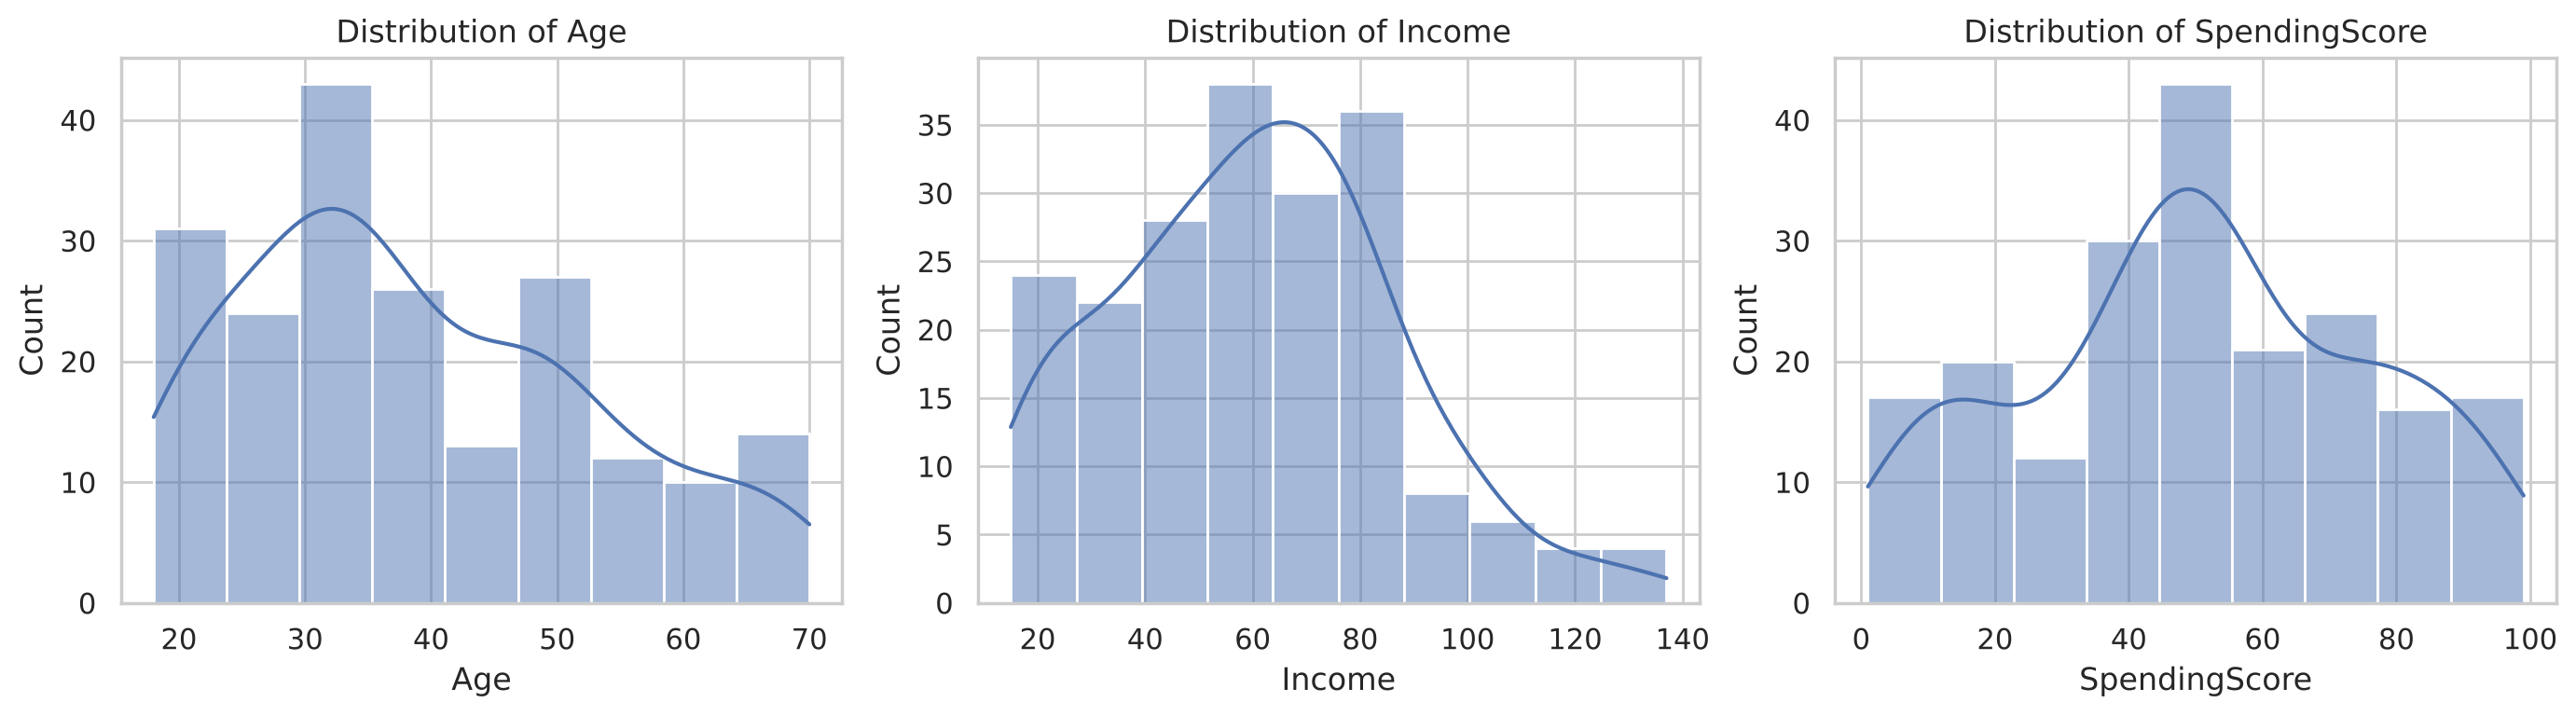

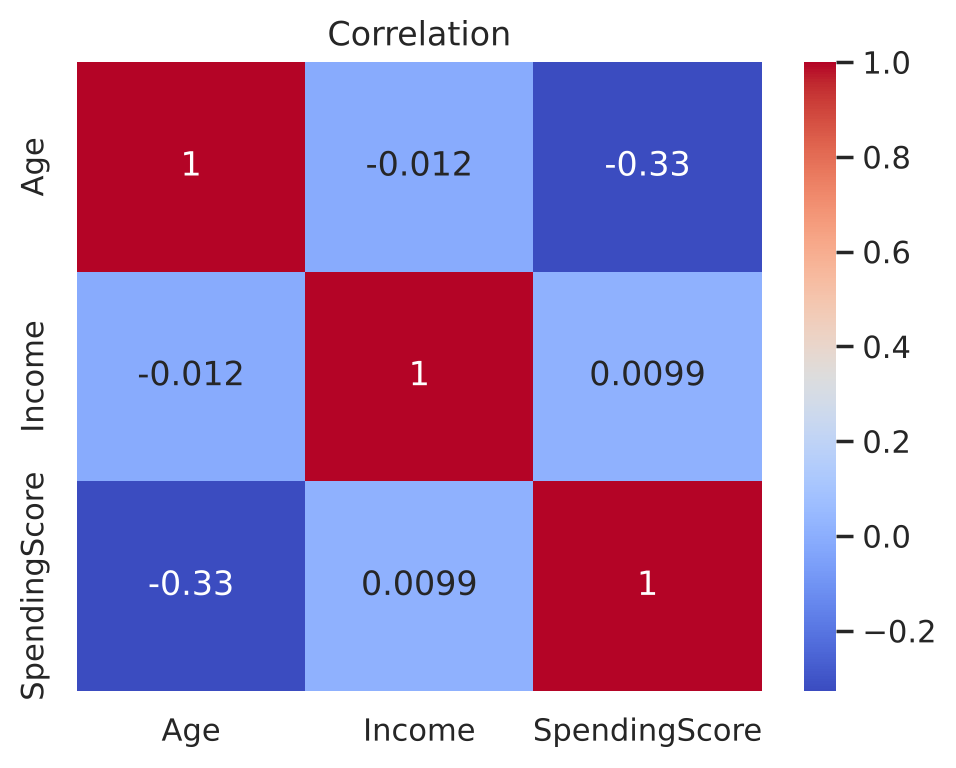

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["Age", "Income", "SpendingScore"]):
    sns.histplot(df[c], kde=True, ax=ax); ax.set_title(f"Distribution of {c}")
fig.tight_layout(); fig.savefig(OUT / "01_distributions.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(df[["Age", "Income", "SpendingScore"]].corr(), annot=True, cmap="coolwarm", ax=ax)
ax.set_title("Correlation"); fig.tight_layout()
fig.savefig(OUT / "02_correlation.png", dpi=130); plt.show()

## 3. Feature selection + scaling

In [4]:
features = ["Age", "Income", "SpendingScore"]
X = StandardScaler().fit_transform(df[features])

## 4. Choose k: elbow + silhouette

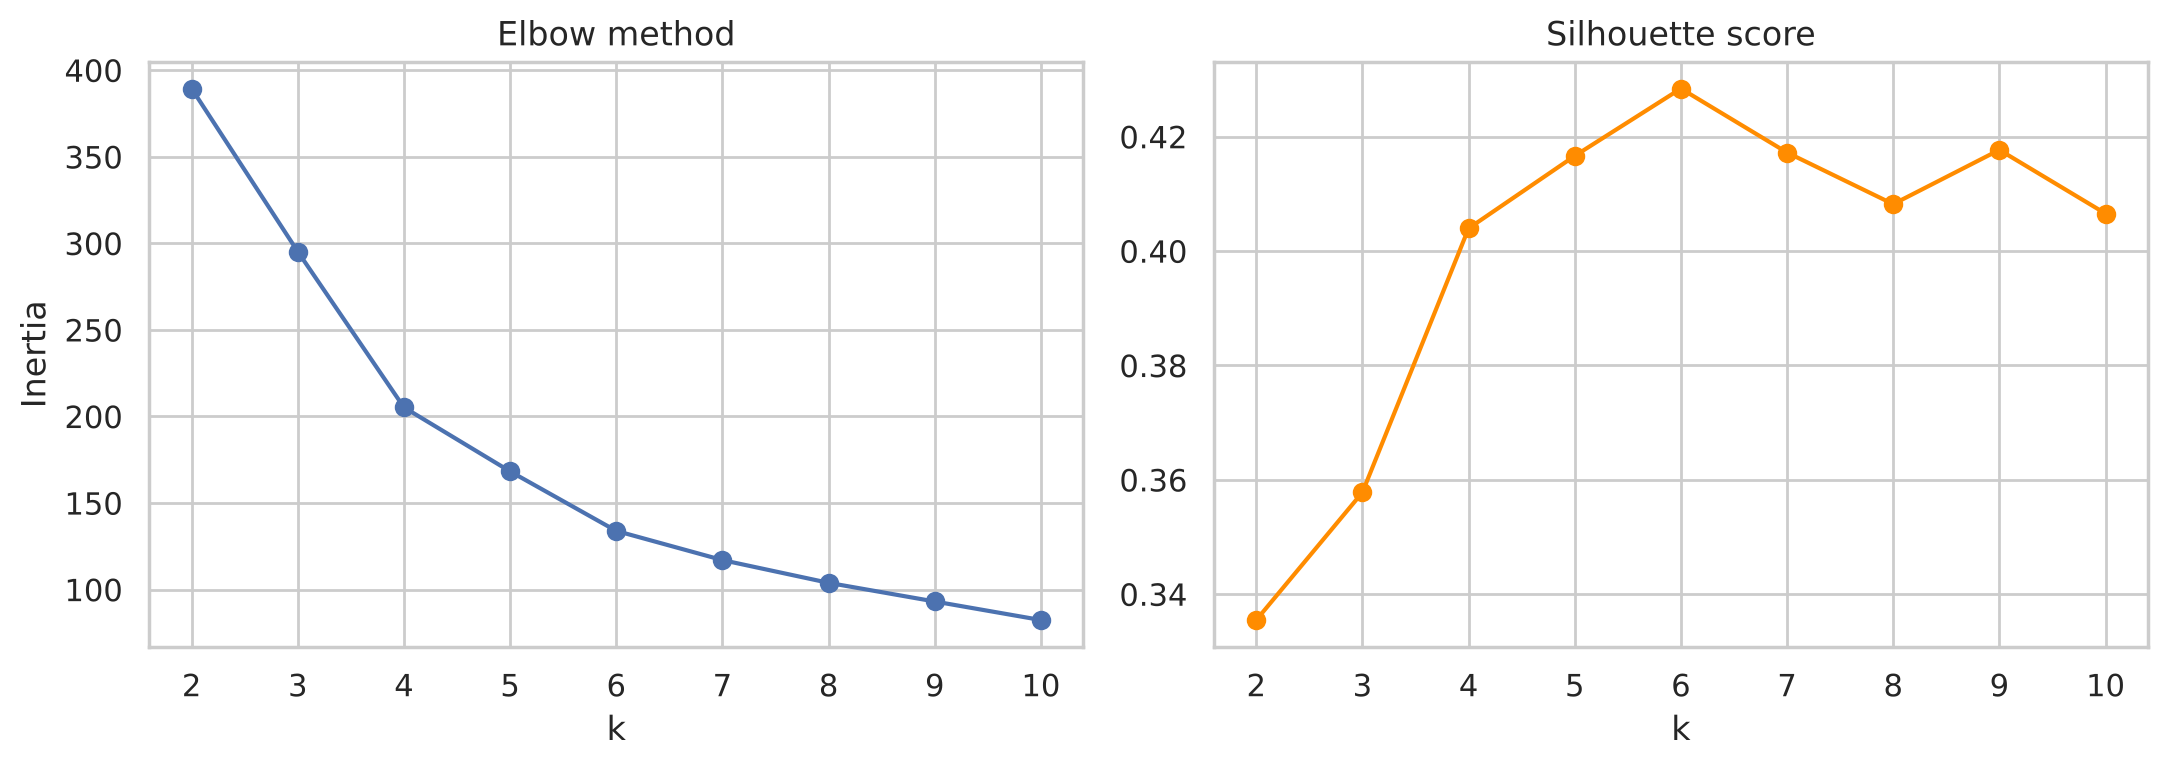

Silhouette per k: {2: np.float64(0.335), 3: np.float64(0.358), 4: np.float64(0.404), 5: np.float64(0.417), 6: np.float64(0.428), 7: np.float64(0.417), 8: np.float64(0.408), 9: np.float64(0.418), 10: np.float64(0.407)} -> best k = 6


In [5]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(ks), sil, "o-", color="darkorange"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
fig.tight_layout(); fig.savefig(OUT / "03_elbow_silhouette.png", dpi=130); plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).to_csv(OUT / "k_selection.csv", index=False)
best_k = list(ks)[int(np.argmax(sil))]
print("Silhouette per k:", dict(zip(ks, np.round(sil, 3))), "-> best k =", best_k)

## 5. Final model

In [6]:
K = best_k
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
df["Cluster"] = km.labels_

## 6. Visualise

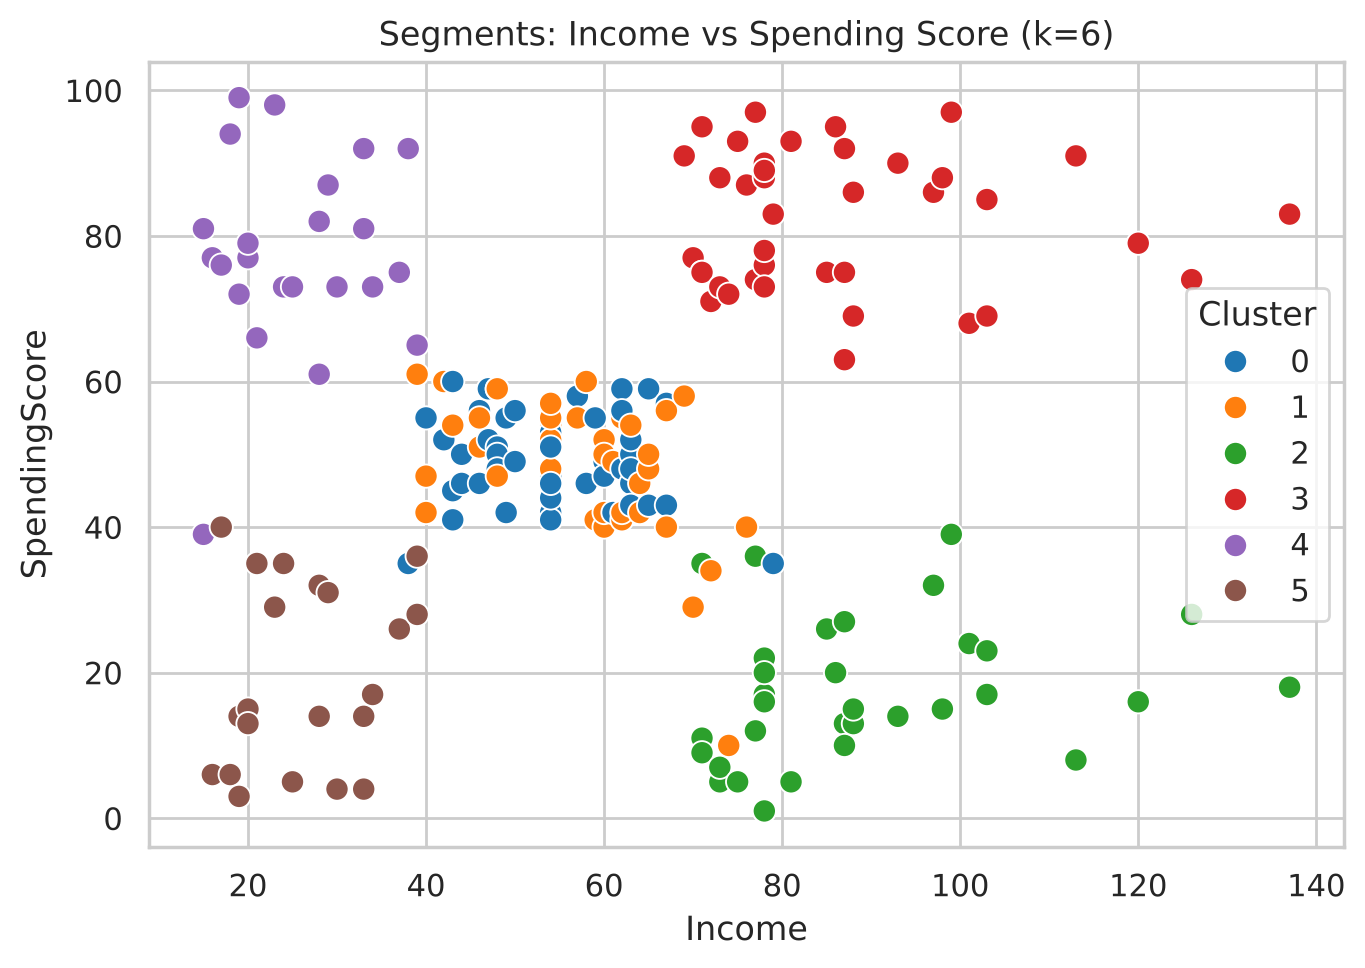

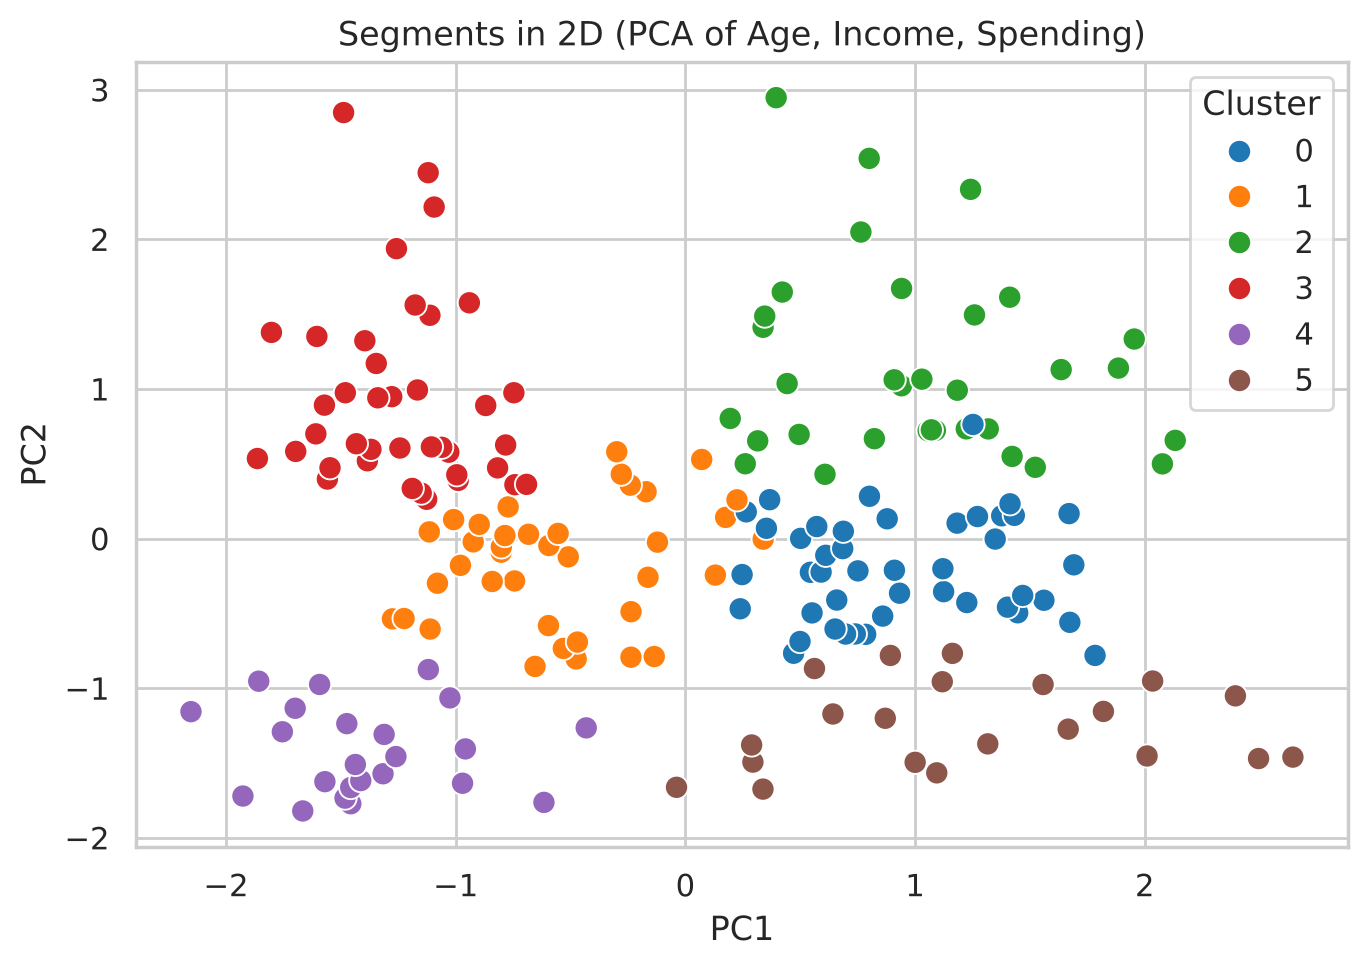

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="Income", y="SpendingScore", hue="Cluster", palette="tab10", s=70, ax=ax)
ax.set_title(f"Segments: Income vs Spending Score (k={K})")
fig.tight_layout(); fig.savefig(OUT / "04_clusters_income_spending.png", dpi=130); plt.show()

pcs = PCA(n_components=2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["Cluster"], palette="tab10", s=70, ax=ax)
ax.set_title("Segments in 2D (PCA of Age, Income, Spending)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.tight_layout(); fig.savefig(OUT / "05_clusters_pca.png", dpi=130); plt.show()

## 7. Profile each segment

         customers  avg_age  avg_income  avg_spending  pct_female
Cluster                                                          
0               45     56.3        54.3          49.1        57.8
1               39     26.8        57.1          48.1        64.1
2               33     41.9        88.9          17.0        42.4
3               39     32.7        86.5          82.1        53.8
4               23     25.0        25.3          77.6        56.5
5               21     45.5        26.3          19.4        61.9


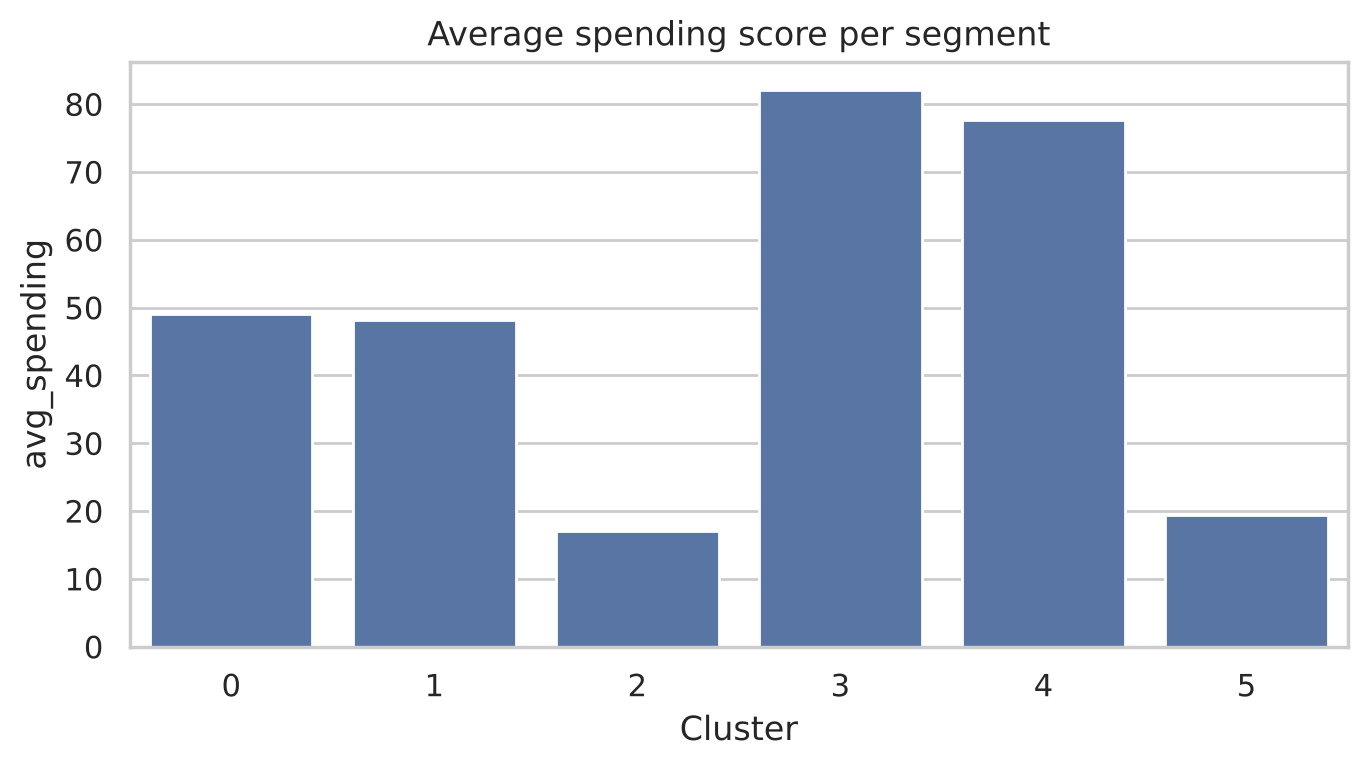

         customers                               segment_name
Cluster                                                      
0               45    Average income, Average spending, older
1               39  Average income, Average spending, younger
2               33     High income, Low spending, middle-aged
3               39    High income, High spending, middle-aged
4               23         Low income, High spending, younger
5               21      Low income, Low spending, middle-aged


In [8]:
profile = df.groupby("Cluster").agg(
    customers=("CustomerID", "count"), avg_age=("Age", "mean"),
    avg_income=("Income", "mean"), avg_spending=("SpendingScore", "mean"),
    pct_female=("Gender", lambda s: (s == "Female").mean() * 100)).round(1)
print(profile.to_string())

def level(v, series, hi="High", lo="Low", mid="Average"):
    z = (v - series.mean()) / series.std()
    return hi if z > 0.5 else lo if z < -0.5 else mid

def label(r):
    inc = level(r.avg_income, df.Income)
    spn = level(r.avg_spending, df.SpendingScore)
    age = level(r.avg_age, df.Age, hi="older", lo="younger", mid="middle-aged")
    return f"{inc} income, {spn} spending, {age}"
profile["segment_name"] = profile.apply(label, axis=1)
profile.to_csv(OUT / "segment_profile.csv")
df.to_csv(OUT / "customers_with_segments.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=profile.index, y=profile["avg_spending"], ax=ax)
ax.set_title("Average spending score per segment"); ax.set_xlabel("Cluster")
fig.tight_layout(); fig.savefig(OUT / "06_segment_spending.png", dpi=130); plt.show()
print(profile[["customers", "segment_name"]].to_string())